# Political Embeddings — Multidimensional Scaling (MDS) Analysis

This notebook applies **Multidimensional Scaling (MDS)** to the dense political sentence embeddings (`data/out/political_embeddings.parquet`) to project them onto low-dimensional manifolds while preserving pairwise geometric distances.

### Why MDS?
* While PCA seeks linear orthogonal axes of maximal variance, MDS attempts to preserve pairwise distances between data points in low-dimensional Euclidean space.
* Because sentence embeddings are $L_2$-normalized, Euclidean distances are monotonically related to cosine dissimilarities ($d_E^2 = 2 - 2\cos$).
* MDS has an $O(N^2)$ memory and computational complexity, so fitting is typically performed on a representative sample (e.g. 2,000–5,000 videos).

### Workflow:
1. **Load Embeddings**: Read precomputed $d=768$ embeddings from `data/out/political_embeddings.parquet`.
2. **Sample**: Extract a representative sample (default `2,500` videos) for fast computation.
3. **Fit MDS**: Compute 2D MDS coordinates using `sklearn.manifold.MDS`.
4. **Visualizations** (matching `pca.ipynb` layout):
   * **1D Jitter Strip Plot**: A 1D ideological continuum along MDS Dimension 1.
   * **2D MDS Scatter Plot**: 2D projection colored by continuous ideological `slant`.
   * **Dual Comparison**: Side-by-side comparison of Ideological Slant vs. Political Saliency.
   * **Channel KDE Distributions**: Density distributions for prominent channels along MDS-1.
   * **Exemplar Inspection**: Extreme Left, Centrist, and Right videos along MDS Dimension 1.

In [1]:
import sys
from pathlib import Path

# Add src directory to path
ROOT = Path("../")
sys.path.insert(0, str(ROOT / "src"))

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import MDS

from config import OUT_DIR

# Aesthetics configuration
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120

## 1. Load Precomputed Political Embeddings
Read `data/out/political_embeddings.parquet`.

In [2]:
embeddings_path = OUT_DIR / "political_embeddings.parquet"
print(f"Reading embeddings from: {embeddings_path}")
df = pl.read_parquet(embeddings_path)

print(f"Loaded {len(df):,} total political videos.")
df.select(["id", "channel", "title", "slant", "political_saliency"]).head(5)

Reading embeddings from: /Users/gustavidunsloth/Documents/Data Science/youtube-ideology-classifier/nbs/../data/out/political_embeddings.parquet
Loaded 111,967 total political videos.


id,channel,title,slant,political_saliency
str,str,str,f64,f64
"""oWZEHs5Covo""","""Vital Information""","""The narrative is crumbling.""",-0.230769,1.0
"""_XOerG5R290""","""Dr. John Campbell""","""South Africa Omicron""",0.15789,0.5
"""rDujVSXYcrY""","""Jimmy Kimmel Live""","""President Obama Says First Lad…",-0.56098,0.5
"""uNXDplgft_g""","""Atun-Shei Films""","""King Philip's War: The Most Im…",-0.61644,0.8
"""0YCk1FyxC68""","""MyNIRS""","""Building Safeguards into Pensi…",-0.666667,0.5


## 2. Sample Data for MDS
Because MDS constructs an $N \times N$ distance matrix ($O(N^2)$ complexity), sampling 2,000 to 5,000 points yields fast, high-fidelity embeddings in seconds.

In [3]:
SAMPLE_SIZE = 2500  # Configurable: e.g. 2000 to 5000
SEED = 42

if SAMPLE_SIZE is not None and SAMPLE_SIZE < len(df):
    df_sample = df.sample(SAMPLE_SIZE, seed=SEED)
    print(f"Sampled {len(df_sample):,} videos for MDS.")
else:
    df_sample = df
    print(f"Using {len(df_sample):,} videos.")

X = np.array(df_sample["embedding"].to_list(), dtype=np.float32)
print(f"Feature matrix shape: {X.shape}")

Sampled 2,500 videos for MDS.
Feature matrix shape: (2500, 768)


## 3. Fit Multidimensional Scaling (MDS)
Fit 2D MDS to preserve pairwise distance relationships.

In [4]:
print(f"Fitting 2D MDS on {len(X):,} embeddings...")

mds = MDS(
    n_components=2,
    init="random",
    random_state=SEED,
    n_init=1,
    max_iter=300,
    n_jobs=-1,
    normalized_stress="auto"
)

coords = mds.fit_transform(X)
print(f"MDS fitting complete! Stress: {mds.stress_:.2f}")

# Merge MDS coordinates into DataFrame
plot_df = df_sample.to_pandas().copy()
plot_df["mds_1"] = coords[:, 0]
plot_df["mds_2"] = coords[:, 1]

# Align orientation so positive MDS-1 correlates with Right-wing slant
corr = np.corrcoef(plot_df["mds_1"], plot_df["slant"].fillna(0))[0, 1]
if corr < 0:
    print(f"Aligning axis orientation (corr={corr:.3f}) so Right is positive...")
    plot_df["mds_1"] = -plot_df["mds_1"]

plot_df.head(5)

Fitting 2D MDS on 2,500 embeddings...
MDS fitting complete! Stress: 61957.25
Aligning axis orientation (corr=-0.485) so Right is positive...


,id,channel,title,slant,political_saliency,embedding,mds_1,mds_2
0,STXwmr01J0o,Pathe,EIFFEL - Official Trailer,-0.818180,0.5,"[0.0469999797642231, 0.08299597352743149, 0.01...",-0.376553,0.089642
1,r-cW1ct5PMA,Gerd Leonhard,The #future is #mindboggling - Futurist #Keyno...,-0.760000,0.5,"[0.04098751023411751, 0.05855567380785942, 0.0...",0.068019,-0.301129
2,pe1ujRL_P6c,CBS Evening News,U.S. and Russia clash over Ukraine during UN m...,0.882350,1.0,"[0.02997947484254837, 0.043917324393987656, 0....",-0.018081,-0.021434
3,-49sRhOU4dU,Lewis Black,Lewis Black's Rantcast #51 - We Are The Variant,-0.631579,1.0,"[0.045102063566446304, 0.05234159529209137, 0....",-0.183225,-0.353200
4,psvytm0baj4,FedScoop,Frank Abagnale on how to protect against ID th...,0.777780,0.5,"[0.019293176010251045, 0.08229321241378784, 0....",0.226112,0.026194


## 4. Visualizations

### Plot A: 1D MDS Jitter Strip Plot (Matching `pca.ipynb` Layout)
A continuous 1D visualization with subtle vertical jitter to display the latent ideological distribution.

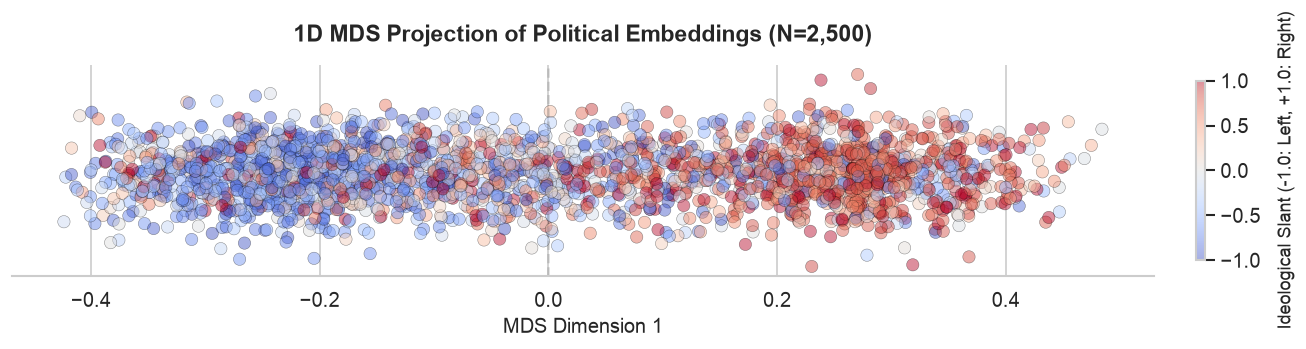

In [6]:
fig, ax = plt.subplots(figsize=(12, 3))

# Random vertical jitter to reveal density
y_vals = np.random.normal(loc=0, scale=0.02, size=len(plot_df))

scatter = ax.scatter(
    plot_df["mds_1"],
    y_vals,
    c=plot_df["slant"],
    cmap="coolwarm",
    alpha=0.45,
    edgecolors="black",
    linewidth=0.3,
    s=55
)

cbar = plt.colorbar(scatter, ax=ax, shrink=0.85, pad=0.03)
cbar.set_label("Ideological Slant (-1.0: Left, +1.0: Right)", fontsize=11, labelpad=10)

ax.set_title(
    f"1D MDS Projection of Political Embeddings (N={len(plot_df):,})",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("MDS Dimension 1", fontsize=12)

# Clean up borders
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.axvline(0, color="grey", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Plot B: 2D MDS Embedding Projection Colored by Ideological Slant
* Blue = Left / Liberal (-1.0)
* Red = Right / Conservative (+1.0)

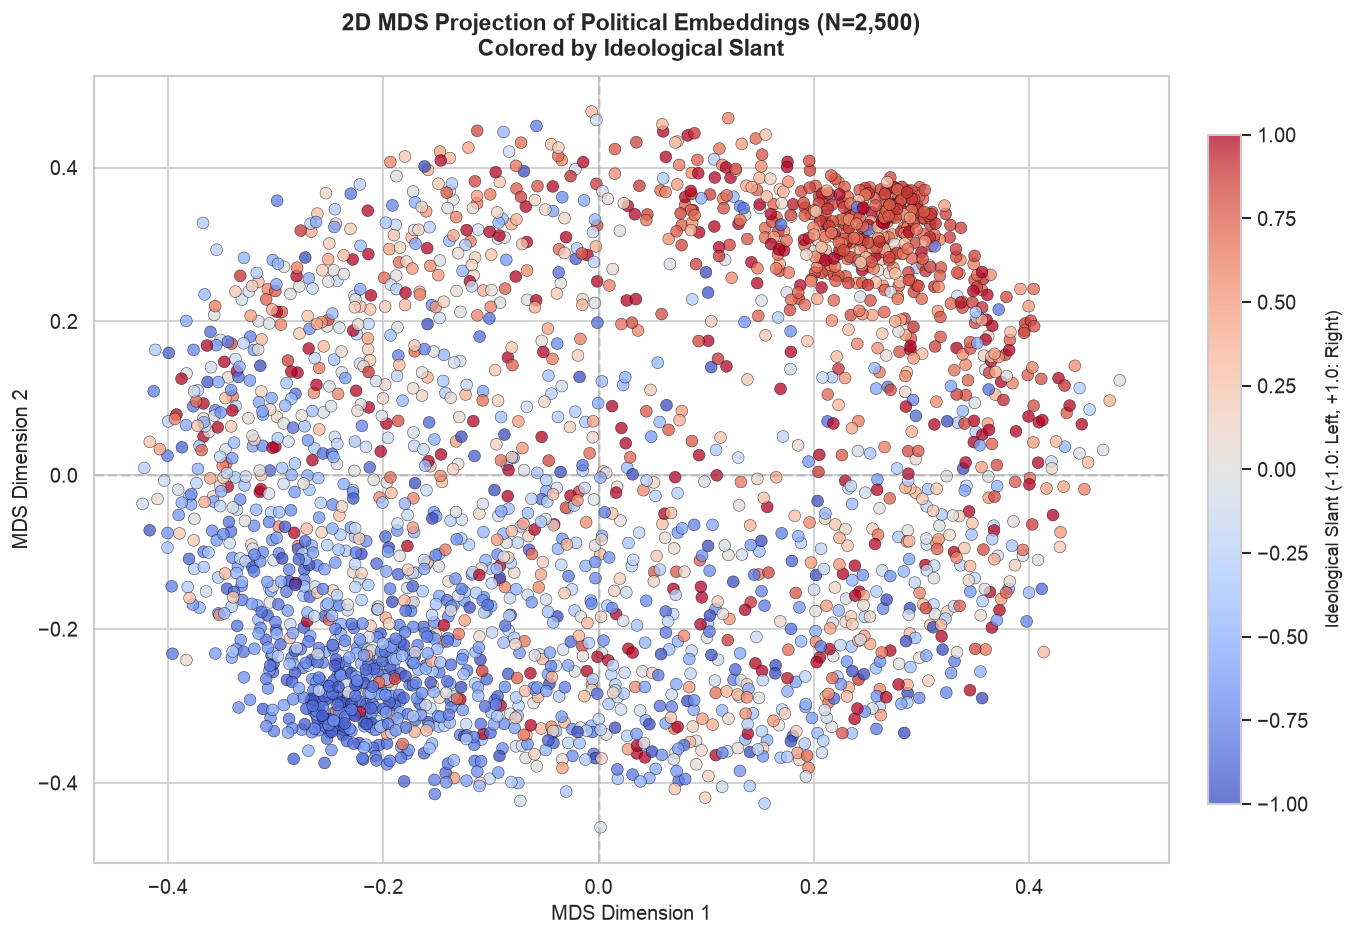

In [7]:
fig, ax = plt.subplots(figsize=(12, 8))

scatter = ax.scatter(
    plot_df["mds_1"],
    plot_df["mds_2"],
    c=plot_df["slant"],
    cmap="coolwarm",
    alpha=0.75,
    edgecolors="black",
    linewidth=0.3,
    s=50
)

cbar = plt.colorbar(scatter, ax=ax, shrink=0.85, pad=0.03)
cbar.set_label("Ideological Slant (-1.0: Left, +1.0: Right)", fontsize=11, labelpad=10)

ax.set_title(
    f"2D MDS Projection of Political Embeddings (N={len(plot_df):,})\nColored by Ideological Slant",
    fontsize=14,
    fontweight="bold",
    pad=12
)
ax.set_xlabel("MDS Dimension 1", fontsize=12)
ax.set_ylabel("MDS Dimension 2", fontsize=12)
ax.axhline(0, color="grey", linestyle="--", alpha=0.3)
ax.axvline(0, color="grey", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Plot C: Dual Comparison — Ideological Slant vs. Political Saliency
Compare how MDS positions align with ideology versus political commentary intensity.

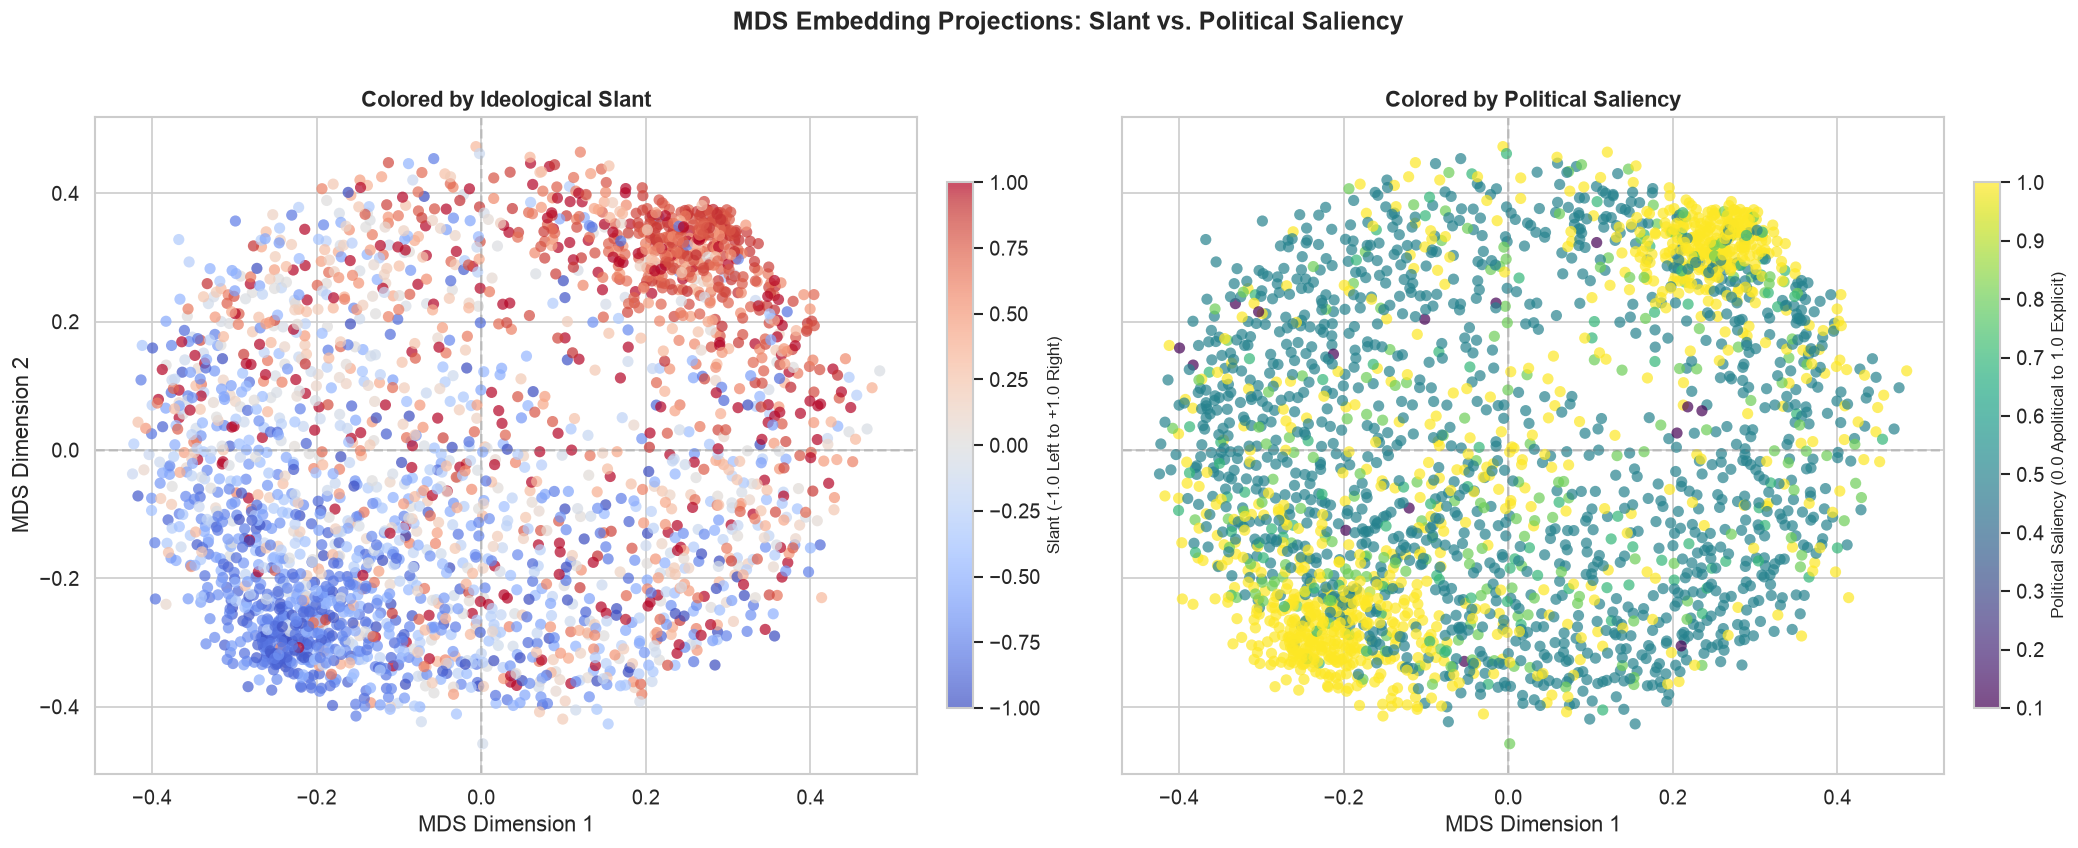

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# 1. Slant
sc1 = axes[0].scatter(
    plot_df["mds_1"],
    plot_df["mds_2"],
    c=plot_df["slant"],
    cmap="coolwarm",
    alpha=0.7,
    edgecolors="none",
    s=45
)
cb1 = plt.colorbar(sc1, ax=axes[0], shrink=0.8, pad=0.03)
cb1.set_label("Slant (-1.0 Left to +1.0 Right)", fontsize=10)
axes[0].set_title("Colored by Ideological Slant", fontsize=13, fontweight="bold")
axes[0].set_xlabel("MDS Dimension 1")
axes[0].set_ylabel("MDS Dimension 2")
axes[0].axhline(0, color="grey", linestyle="--", alpha=0.3)
axes[0].axvline(0, color="grey", linestyle="--", alpha=0.3)

# 2. Political Saliency
sc2 = axes[1].scatter(
    plot_df["mds_1"],
    plot_df["mds_2"],
    c=plot_df["political_saliency"],
    cmap="viridis",
    alpha=0.7,
    edgecolors="none",
    s=45
)
cb2 = plt.colorbar(sc2, ax=axes[1], shrink=0.8, pad=0.03)
cb2.set_label("Political Saliency (0.0 Apolitical to 1.0 Explicit)", fontsize=10)
axes[1].set_title("Colored by Political Saliency", fontsize=13, fontweight="bold")
axes[1].set_xlabel("MDS Dimension 1")
axes[1].axhline(0, color="grey", linestyle="--", alpha=0.3)
axes[1].axvline(0, color="grey", linestyle="--", alpha=0.3)

plt.suptitle("MDS Embedding Projections: Slant vs. Political Saliency", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### Plot D: Channel Ideological Distributions (KDE Density Plots)
Density distributions for top news and political commentary channels along MDS Dimension 1.

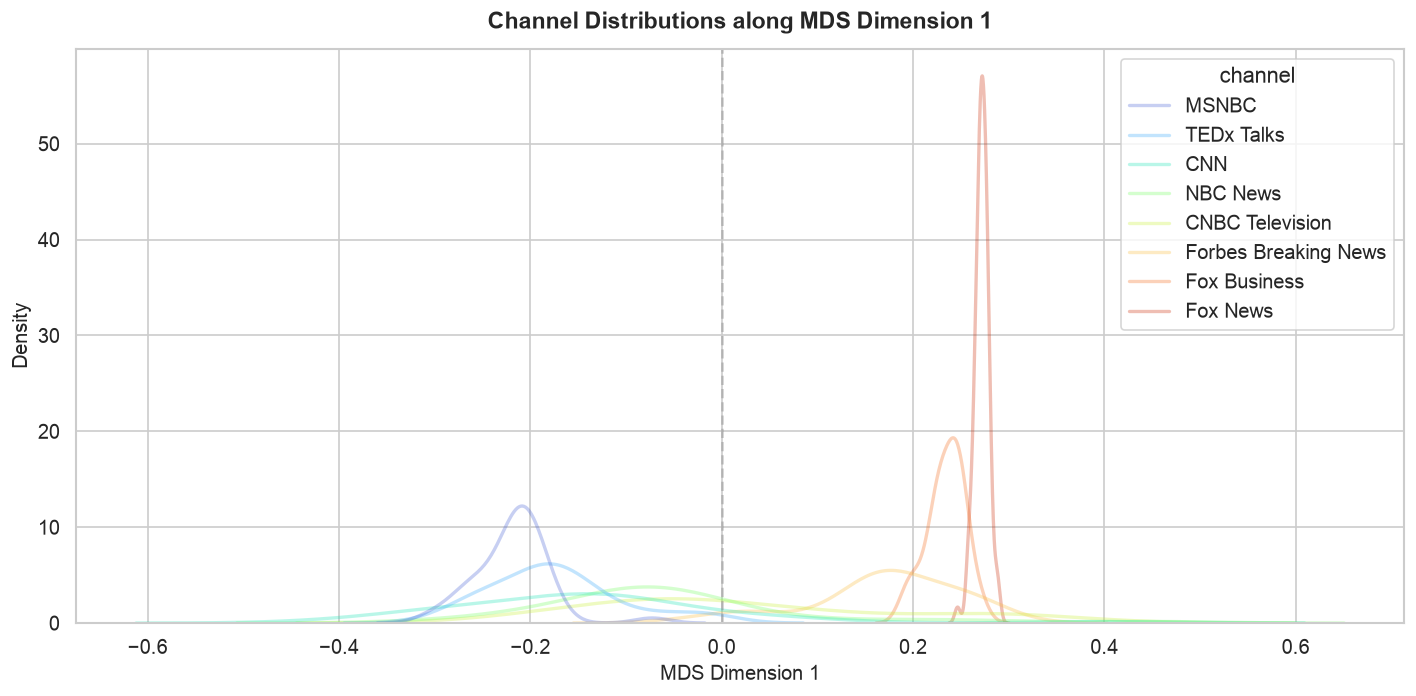

In [10]:
# Filter for top channels with sufficient representation in the sample
top_channel_counts = plot_df["channel"].value_counts()
candidate_channels = top_channel_counts.head(8).index.tolist()
df_channels = plot_df[plot_df["channel"].isin(candidate_channels)].copy()

# Order channels by median MDS-1 coordinate
channel_order = (
    df_channels.groupby("channel")["mds_1"]
    .median()
    .sort_values()
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.kdeplot(
    data=df_channels,
    x="mds_1",
    hue="channel",
    hue_order=channel_order,
    common_norm=False,
    alpha=0.3,
    linewidth=2,
    palette="turbo",
    ax=ax
)

ax.set_title("Channel Distributions along MDS Dimension 1", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("MDS Dimension 1", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.axvline(0, color="grey", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 5. Semantic Inspection of Exemplar Videos
Inspect the most extreme Left-leaning, Centrist, and Right-leaning videos along MDS Dimension 1.

In [11]:
print("="*90)
print("🔹 TOP 5 MOST LEFT-LEANING VIDEOS (Lowest MDS Dimension 1)")
print("="*90)
left_videos = plot_df.sort_values("mds_1").head(5)
for _, v in left_videos.iterrows():
    print(f"• [{v['mds_1']:+.3f}] [{v['channel']}] {v['title'][:65]} (Slant: {v['slant']:+.2f})")

print("\n" + "="*90)
print("🔹 TOP 5 CENTRIST / MODERATE VIDEOS (Closest to Median MDS-1)")
print("="*90)
median_mds = plot_df["mds_1"].median()
center_videos = plot_df.iloc[(plot_df["mds_1"] - median_mds).abs().argsort()[:5]]
for _, v in center_videos.iterrows():
    print(f"• [{v['mds_1']:+.3f}] [{v['channel']}] {v['title'][:65]} (Slant: {v['slant']:+.2f})")

print("\n" + "="*90)
print("🔹 TOP 5 MOST RIGHT-LEANING VIDEOS (Highest MDS Dimension 1)")
print("="*90)
right_videos = plot_df.sort_values("mds_1", ascending=False).head(5)
for _, v in right_videos.iterrows():
    print(f"• [{v['mds_1']:+.3f}] [{v['channel']}] {v['title'][:65]} (Slant: {v['slant']:+.2f})")

🔹 TOP 5 MOST LEFT-LEANING VIDEOS (Lowest MDS Dimension 1)
• [-0.424] [Seven Hip-Hop] 2Pac - Hit 'Em Up (Dirty) (Music Video) HD (Slant: -0.14)
• [-0.422] [KanyeWestVEVO] Kanye West - Runaway (Full-length Film) (Slant: -0.28)
• [-0.417] [F.D Signifier] Dave Chappelle Only Tells Half the Truth (Slant: -0.94)
• [-0.417] [Snutchi] Charles Manson Epic Answer (Full Answer) (Slant: +0.27)
• [-0.413] [MozzyVEVO] Mozzy - Real Ones ft. Roddy Ricch (Official Music Video) ft. Rodd (Slant: -0.78)

🔹 TOP 5 CENTRIST / MODERATE VIDEOS (Closest to Median MDS-1)
• [-0.026] [ABC News] Biden warns Russian invasion of Ukraine will bring 'swift and sev (Slant: +1.00)
• [-0.026] [Cambridge Law Faculty] 'Reflections on the Rule of Law in a Dangerous World': The 2018 S (Slant: -0.88)
• [-0.026] [Loza Alexander] #letsgobrandonchallenge (Slant: +0.93)
• [-0.027] [USA TODAY] Inmates rush from cells to save deputy's life | Humankind (Slant: +0.18)
• [-0.025] [The Economist] Is America in decline? (Slant: -0.21)

🔹